# 03 — Sentence-BERT + logistic regression

Model 2 encodes the claim and each evidence pair with Sentence-BERT, mean-pools the evidence, and builds `[u, v, |u-v|, u*v, has_evidence]` for the full input mode. Logistic regression uses the same `C` grid, stratified folds, and macro-F1 as the TF-IDF model. This notebook only reads the saved metrics, predictions, and the claim projection.

In [1]:
from pathlib import Path
import sys

import pandas as pd
from IPython.display import Image, Markdown, display

ROOT = Path.cwd().resolve()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from src import config as C
from src.evaluate import load_metrics, load_predictions
from src.utils import read_json

rows = []
for mode in C.INPUT_MODES:
    metrics = load_metrics("sbert_lr", mode)
    if metrics is None:
        raise FileNotFoundError(f"Missing results/metrics/sbert_lr_{mode}.json")
    rows.append({
        "input_mode": mode,
        "accuracy": metrics["accuracy"],
        "macro_f1": metrics["macro_f1"],
        "macro_f1_ci95": metrics["macro_f1_ci95"],
        "cv_macro_f1": metrics["cv_macro_f1"],
        "best_C": metrics["best_params"].get("C"),
        "sbert_model": (metrics.get("extra") or {}).get("sbert_model"),
        "train_seconds": metrics["train_seconds"],
    })
summary = pd.DataFrame(rows)
summary


,input_mode,accuracy,macro_f1,macro_f1_ci95,cv_macro_f1,best_C,sbert_model,train_seconds
0,full,0.494867,0.359564,"[0.311471, 0.409804]",0.407182,0.01,sentence-transformers/all-MiniLM-L6-v2,4.725738
1,claim_only,0.435318,0.316480,"[0.270317, 0.3629]",0.333676,0.01,sentence-transformers/all-MiniLM-L6-v2,2.716878
2,evidence_only,0.451745,0.351983,"[0.309713, 0.395743]",0.408137,0.01,sentence-transformers/all-MiniLM-L6-v2,2.754682


## What the three input modes use

`claim_only` keeps the claim embedding. `evidence_only` keeps the pooled evidence embedding and the missing-evidence flag. `full` adds the absolute difference and the element-wise product.

In [2]:
sidecar = read_json(C.MODELS_DIR / "sbert_lr_full.json")
sidecar


{'sbert_model': 'sentence-transformers/all-MiniLM-L6-v2',
 'feature_mode': 'full'}

## Test predictions

A few full-mode predictions. `correct` is 1 when the predicted verdict matches the recorded label.

In [3]:
predictions = load_predictions("sbert_lr", "full")
predictions.head(8)


,claim_id,y_true,y_pred,correct,proba_Supported,proba_Refuted,proba_Not Enough Evidence,proba_Conflicting Evidence/Cherrypicking
0,0,Refuted,Refuted,1,0.007853,0.574936,0.262294,0.154917
1,1,Refuted,Refuted,1,0.288615,0.710757,0.000068,0.000560
2,2,Refuted,Refuted,1,0.004022,0.985043,0.007098,0.003837
3,3,Refuted,Refuted,1,0.294440,0.524646,0.129898,0.051016
4,4,Refuted,Refuted,1,0.009348,0.967979,0.006198,0.016475
5,5,Refuted,Refuted,1,0.069031,0.922395,0.005523,0.003050
6,6,Supported,Refuted,0,0.212231,0.629223,0.074328,0.084219
7,7,Supported,Supported,1,0.963712,0.009407,0.010472,0.016409


## Claim embeddings

Test claims projected from the MiniLM embedding. Color is the true label.

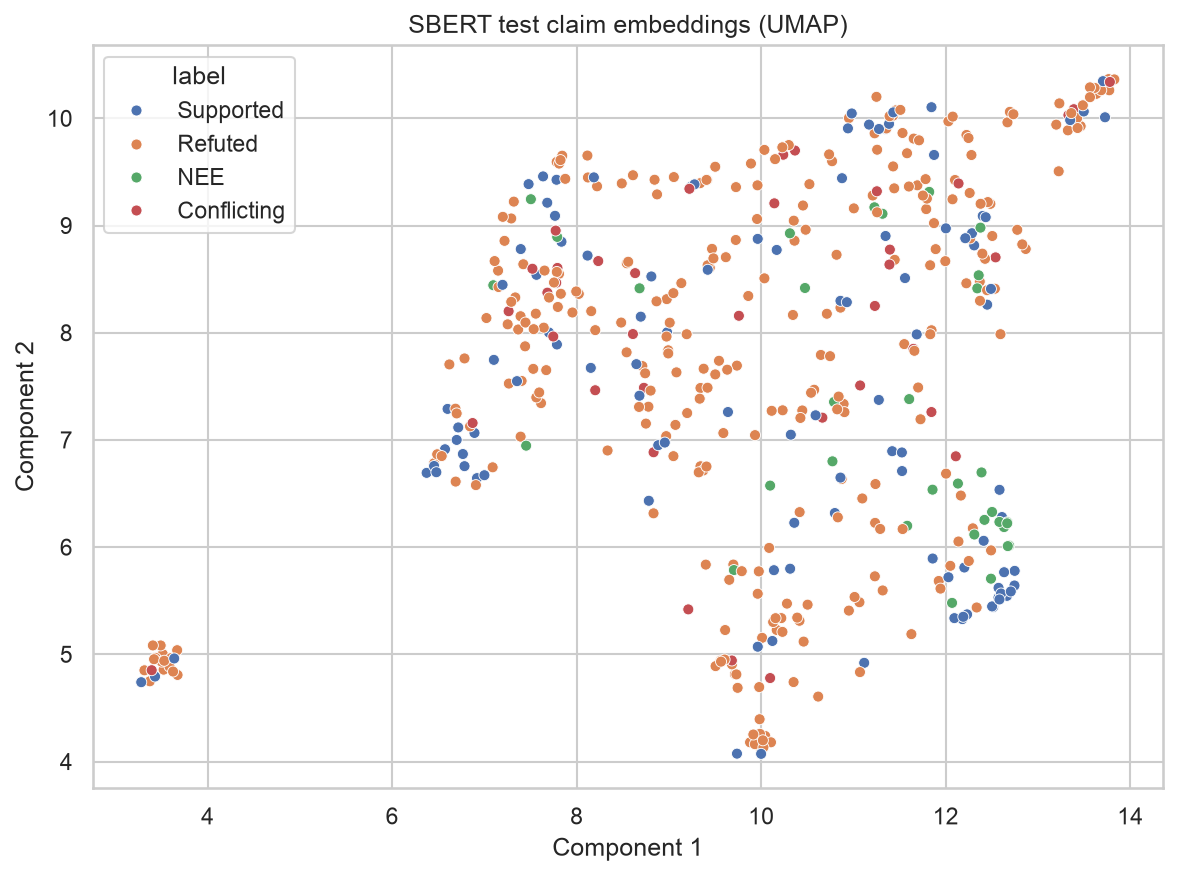

In [4]:
figure = C.FIGURES_DIR / "sbert_umap_claims.png"
if not figure.exists():
    raise FileNotFoundError(figure)
display(Image(filename=str(figure)))
